# Práctica guiada · Ajuste de hiperparámetros con tres clasificadores
### Regresión logística · SVM · Naive Bayes

**FP13 · Inteligencia Artificial** —  Universidad Autónoma de Guadalajara

**Unidad 5:** 5.5 Regresión logística · 5.6 Naive Bayes · 5.7 Matrices de confusión · 5.8 SVM — con adelanto de **6.5 Búsqueda de rejilla**

---

### 🏥 El problema clínico
Un servicio de cardiología quiere una herramienta de **apoyo al triaje**: con 11 datos clínicos de rutina (edad, tipo de dolor torácico, colesterol, ECG en reposo, frecuencia cardiaca máxima, depresión del segmento ST…) debe decidir si un paciente **probablemente tiene enfermedad cardiaca** y conviene enviarlo a estudios especializados.

In [188]:
# Importando librerias
import warnings
warnings.filterwarnings("ignore")      # oculta avisos técnicos para que la pantalla quede limpia

import numpy as np                     # cálculo numérico
import pandas as pd                    # tablas de datos
import matplotlib.pyplot as plt        # gráficas
import kagglehub                       # descarga datasets de Kaggle

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, confusion_matrix,
                             accuracy_score, recall_score, precision_score, f1_score)

---
## 1 · Los datos

**Heart Failure Prediction Dataset** (fedesoriano, Kaggle): 918 pacientes de cinco cohortes cardiológicas.

| Variable | Significado clínico |
|---|---|
| `Age` | Edad (años) |
| `Sex` | Sexo (M / F) |
| `ChestPainType` | Dolor torácico: TA angina típica · ATA atípica · NAP no anginoso · ASY asintomático |
| `RestingBP` | Presión arterial sistólica en reposo (mm Hg) |
| `Cholesterol` | Colesterol sérico (mg/dL) |
| `FastingBS` | Glucosa en ayuno > 120 mg/dL (1 = sí) |
| `RestingECG` | ECG en reposo: Normal · ST (anomalía ST-T) · LVH (hipertrofia ventricular izquierda) |
| `MaxHR` | Frecuencia cardiaca máxima en prueba de esfuerzo |
| `ExerciseAngina` | Angina inducida por el ejercicio (Y / N) |
| `Oldpeak` | Depresión del segmento ST con el esfuerzo (mm) |
| `ST_Slope` | Pendiente del ST en el pico del esfuerzo: Up · Flat · Down |
| **`HeartDisease`** | **Lo que queremos predecir: 1 = con enfermedad cardiaca · 0 = sin enfermedad** |

In [189]:
# Importando datos
import kagglehub
from kagglehub import KaggleDatasetAdapter
df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS,
                            "fedesoriano/heart-failure-prediction", "heart.csv")

In [190]:
# Explorando dataframe
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [191]:
# Imprimiendo renglones y columnas del dataframe
df.shape

(918, 12)

---
## 2 · Preparar los datos

Tres decisiones, todas vistas en la Unidad 4:
1. **Valores imposibles → faltantes.** Nadie vivo tiene colesterol 0 ni presión arterial 0: son celdas que nadie llenó.
2. **Separar `X` de `y`.** `X` = lo que el modelo puede ver; `y` = la respuesta correcta.
3. **One-hot.** Los modelos solo entienden números, así que cada columna de texto se convierte en columnas de 0 y 1.

In [192]:
# Imprimiendo tipos de datos
df.dtypes

Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

In [193]:
# Comprobando si existen datos nulos
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [194]:
# Explorando los datos numéricos
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


In [195]:
# Corrigiendo los valores numericos en 0 que no hacen sentido

df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)

In [196]:
# Validando la conversión a valores nulos
df.isna().sum()

Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       172
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0
dtype: int64

# Dividiendiendo los Datos y Aplicando One Hot

In [197]:
# Separando los datos en x e y
y = df['HeartDisease']
X = df.drop(columns= ['HeartDisease'])

In [198]:
# Definiendo columnas de tipo caracter o string
string_columns = ['Sex','ChestPainType','RestingECG','ExerciseAngina','ST_Slope']

# Iterando sobre las columnas string
for column in string_columns:
    print(X[column].value_counts())
    print('\n')

Sex
M    725
F    193
Name: count, dtype: int64


ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64


RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64


ExerciseAngina
N    547
Y    371
Name: count, dtype: int64


ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64




In [199]:
# Imprimiendo los datos antes de aplicar el One-Hot
print(X.head())
print(X.shape)

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA      140.0        289.0          0     Normal    172   
1   49   F           NAP      160.0        180.0          0     Normal    156   
2   37   M           ATA      130.0        283.0          0         ST     98   
3   48   F           ASY      138.0        214.0          0     Normal    108   
4   54   M           NAP      150.0        195.0          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  
0              N      0.0       Up  
1              N      1.0     Flat  
2              N      0.0       Up  
3              Y      1.5     Flat  
4              N      0.0       Up  
(918, 11)


In [200]:
# Aplicando One-Hot a las columnas string
X = pd.get_dummies(X, drop_first= True, dtype= int)

# Imprimiendo los datos antes de aplicar el One-Hot
print(X.head())
print(X.shape)

   Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  Sex_M  \
0   40      140.0        289.0          0    172      0.0      1   
1   49      160.0        180.0          0    156      1.0      0   
2   37      130.0        283.0          0     98      0.0      1   
3   48      138.0        214.0          0    108      1.5      0   
4   54      150.0        195.0          0    122      0.0      1   

   ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  RestingECG_Normal  \
0                  1                  0                 0                  1   
1                  0                  1                 0                  1   
2                  1                  0                 0                  0   
3                  0                  0                 0                  1   
4                  0                  1                 0                  1   

   RestingECG_ST  ExerciseAngina_Y  ST_Slope_Flat  ST_Slope_Up  
0              0                 0           

# Haciendo el split de los datos

In [201]:
# Imprimiendo la proporción de la variable objetivo
print(df['HeartDisease'].value_counts(normalize = True))

proporcion = df['HeartDisease'].value_counts(normalize = True)[1]

print('\n')
print(f'Los datos se encuentran casi balanceados ({proporcion: .1%}), pero aún así aplicares estratificación en el split de los datos.')

HeartDisease
1    0.553377
0    0.446623
Name: proportion, dtype: float64


Los datos se encuentran casi balanceados ( 55.3%), pero aún así aplicares estratificación en el split de los datos.


In [202]:
# Dividiendo los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.20, stratify= y, random_state=42)

print(f'Dimensiones del conjunto X de entrenamiento: {X_train.shape}')
print(f'Dimensiones del conjunto X de prueba: {X_test.shape}')

Dimensiones del conjunto X de entrenamiento: (734, 15)
Dimensiones del conjunto X de prueba: (184, 15)


---
## 3 · Repaso: ¿cómo vamos a evaluar?

Las filas son la **realidad** y las columnas lo que **predice** el modelo:

| | Predice **Sano** | Predice **Enfermo** |
|---|:---:|:---:|
| **Realmente sano** | ✅ VN · sano bien descartado | ⚠️ FP · falsa alarma |
| **Realmente enfermo** | ❌ **FN · enfermo que se va a casa** | ✅ VP · enfermo detectado |

<br>

| Métrica | Pregunta clínica que responde | Nombre en `scoring` |
|---|---|---|
| **Exactitud** | De cada 100 pacientes, ¿cuántos clasifica bien? | `"accuracy"` |
| **Precisión** | De cada 100 que el modelo marca como enfermos, ¿cuántos realmente lo están? | `"precision"` |
| **Sensibilidad** | De cada 100 enfermos, ¿a cuántos detecta? | `"recall"` |
| **F1** | Un solo número que exige **a la vez** buena precisión y buena sensibilidad | `"f1"` |
| **AUC** | Si tomo un enfermo y un sano al azar, ¿qué tan seguido el modelo le asigna más riesgo al enfermo? | `"roc_auc"` |
| **Especificidad** | De cada 100 sanos, ¿a cuántos descarta correctamente? | *(es el recall de la clase "Sano")* |

---
# Regresión Logística

In [203]:
# importando la librería de la regresión logística
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer

# columnas numéricas: son las únicas que tienen faltantes y las únicas que escalamos
columnas_escalar = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# a las numéricas: rellenar con la mediana y escalar
# al resto (los 0/1 del one-hot y FastingBS): dejarlas pasar tal cual
prep = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),   # rellena los nulos con la mediana
            ("escalar", StandardScaler()),                   # media 0, desviación 1
        ]), columnas_escalar),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

# Pipeline: preparación → modelo
reglog_base = Pipeline([
    ("prep",   prep),
    ("modelo", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0,
                                  max_iter=5000, random_state=42))
])

# Ajustando modelo con valores por defecto
reglog_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse 

              precision    recall  f1-score   support

        Sano       0.89      0.87      0.88        82
     Enfermo       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184



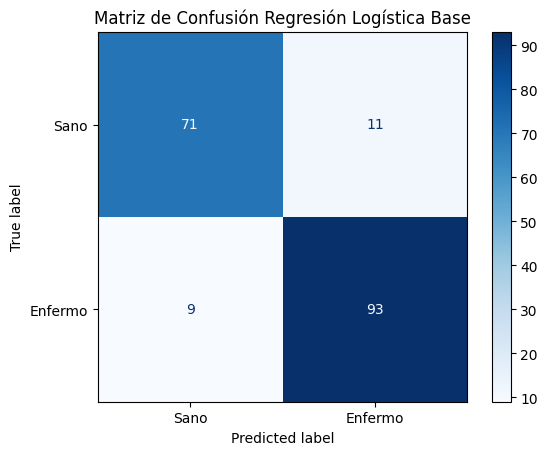

In [204]:
# Equivalencias de la clase objetivo (0 y 1 respectivamente)
clases = ['Sano','Enfermo']

# Metricas para evaluar los modelos
metricas = ['accuracy','precision','recall','f1','roc_auc']

# calculando las predicciones y la matriz de confusión
y_pred = reglog_base.predict(X_test)

# imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')

# Agregando titulo a la gráfica
plt.title('Matriz de Confusión Regresión Logística Base')
plt.show()

In [205]:
# Hiperparametros a optimizar
rejilla_reglog = {
    "modelo__C":            [0.001, 0.01, 0.1, 1, 10, 100],
    "modelo__l1_ratio":     [0, 0.5, 1],             # 0 = L2 · 0.5 = mezcla · 1 = L1
    "modelo__class_weight": [None, "balanced"],
}

In [206]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(reglog_base, rejilla_reglog, scoring= metrica, cv=5, n_jobs= -1)
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {round(busqueda.best_score_, 3)}, {busqueda.best_params_}')

accuracy >> 0.856, {'modelo__C': 0.1, 'modelo__class_weight': None, 'modelo__l1_ratio': 0.5}
precision >> 0.87, {'modelo__C': 10, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 0}
recall >> 1.0, {'modelo__C': 0.001, 'modelo__class_weight': None, 'modelo__l1_ratio': 0.5}
f1 >> 0.872, {'modelo__C': 0.1, 'modelo__class_weight': None, 'modelo__l1_ratio': 0.5}
roc_auc >> 0.915, {'modelo__C': 1, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 1}


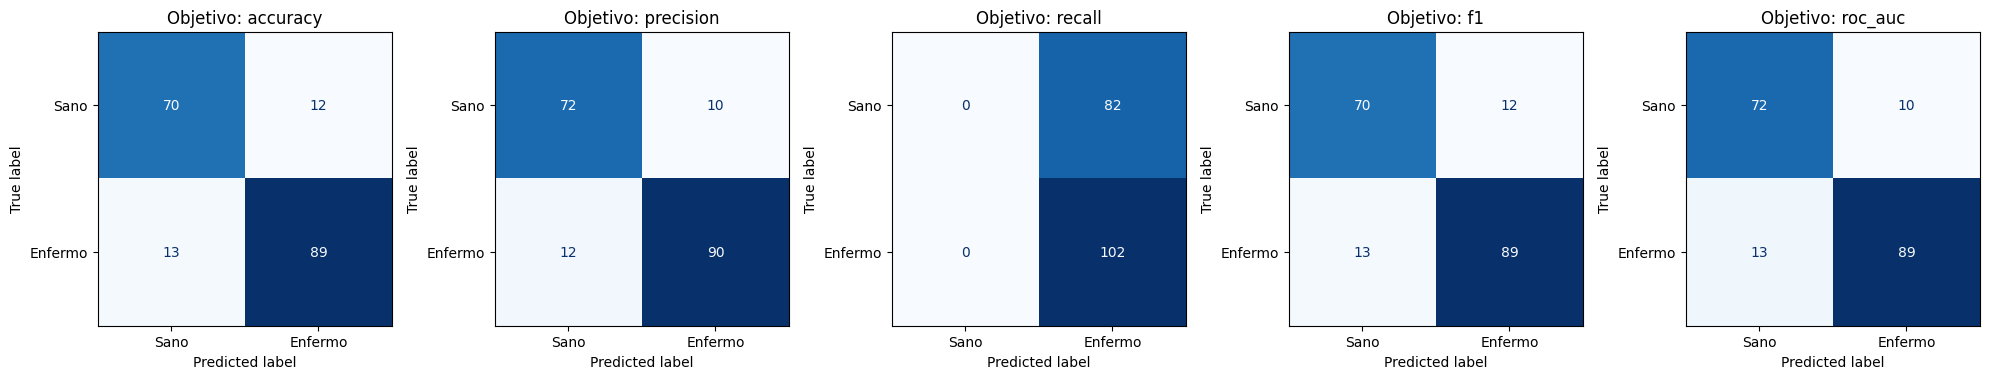

In [207]:
# Mostrando todas las matrices de confusión
fig, ejes = plt.subplots(1, 5, figsize=(20, 4))      # 1 fila con 5 recuadros

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap="Blues", colorbar=False, ax=eje)
    eje.set_title(f"Objetivo: {metrica}")

plt.tight_layout()
plt.show()

In [208]:
# Elegiremos el modelo que optimiza la presicion como mejor modelo, pues maximiza los verdaderos negativos y minimiza los falsos positivos.
# Es decir, identificamos al mayor numero de personas enfermas correctamente y nos equivos en el menor numero en las personas que dijimos eran sanas pero están enfermas.

# Máquinas de Vectores de Soporte (SVM)

In [209]:
# Creando el modelo base
from sklearn.svm import SVC

# Pipeline: preparación → modelo
svm_base = Pipeline([
    ("prep",   prep),
    ("modelo", SVC())
])

# Ajustando modelo con valores por defecto
svm_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse 

              precision    recall  f1-score   support

        Sano       0.85      0.85      0.85        82
     Enfermo       0.88      0.88      0.88       102

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184



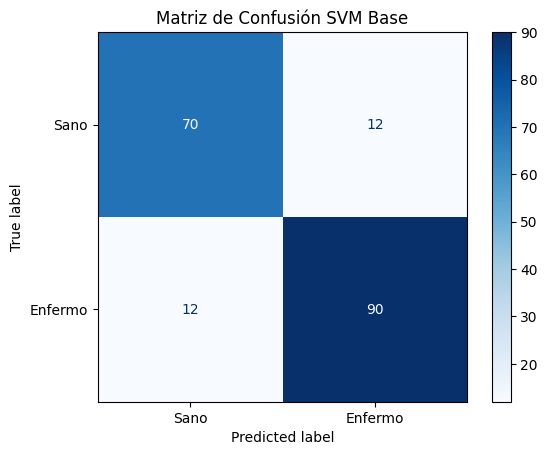

In [210]:
# calculando las predicciones y la matriz de confusión
y_pred = svm_base.predict(X_test)

# imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')

# Agregando titulo a la gráfica
plt.title('Matriz de Confusión SVM Base')
plt.show()

In [211]:
# Definiendo los valor de los hiperparámetros a optimizar
valores_C = [0.001, 0.01, 0.1, 1, 10, 100]

rejilla_svm = [
    {"modelo__kernel":       ["linear"],
     "modelo__C":            valores_C,
     "modelo__class_weight": [None, "balanced"]},

    {"modelo__kernel":       ["rbf"],
     "modelo__C":            valores_C,
     "modelo__gamma":        ["scale", 0.01, 0.1],
     "modelo__class_weight": [None, "balanced"]},
]

In [212]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(svm_base, rejilla_svm, scoring= metrica, cv=5, n_jobs= -1)
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {round(busqueda.best_score_, 3)}, {busqueda.best_params_}')

accuracy >> 0.866, {'modelo__C': 1, 'modelo__class_weight': None, 'modelo__gamma': 0.1, 'modelo__kernel': 'rbf'}
precision >> 0.868, {'modelo__C': 10, 'modelo__class_weight': 'balanced', 'modelo__kernel': 'linear'}
recall >> 1.0, {'modelo__C': 0.001, 'modelo__class_weight': None, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}
f1 >> 0.882, {'modelo__C': 1, 'modelo__class_weight': None, 'modelo__gamma': 0.1, 'modelo__kernel': 'rbf'}
roc_auc >> 0.919, {'modelo__C': 100, 'modelo__class_weight': 'balanced', 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}


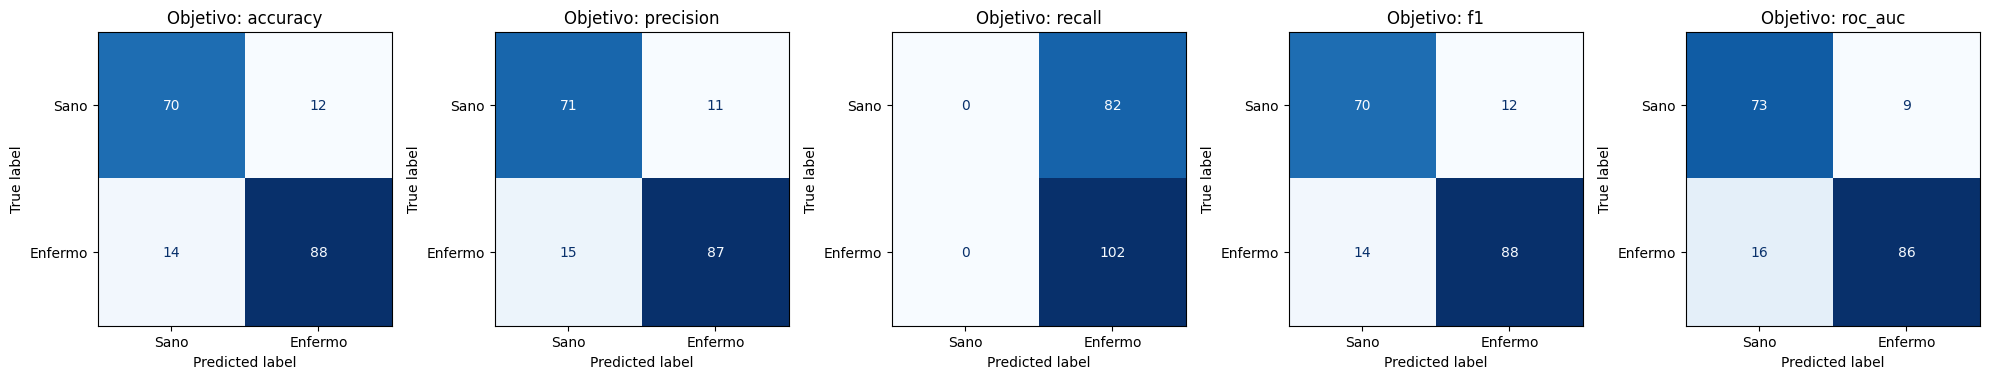

In [213]:
# Mostrando todas las matrices de confusión
fig, ejes = plt.subplots(1, 5, figsize=(20, 4))      # 1 fila con 5 recuadros

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap="Blues", colorbar=False, ax=eje)
    eje.set_title(f"Objetivo: {metrica}")

plt.tight_layout()
plt.show()

# Naive Bayes

In [214]:
# Creando el modelo base
from sklearn.naive_bayes import GaussianNB

# Pipeline: preparación → modelo
nb_base = Pipeline([
    ("prep",   prep),
    ("modelo", GaussianNB())
])

# Ajustando modelo con valores por defecto
nb_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse 

              precision    recall  f1-score   support

        Sano       0.84      0.89      0.86        82
     Enfermo       0.91      0.86      0.88       102

    accuracy                           0.88       184
   macro avg       0.87      0.88      0.87       184
weighted avg       0.88      0.88      0.88       184



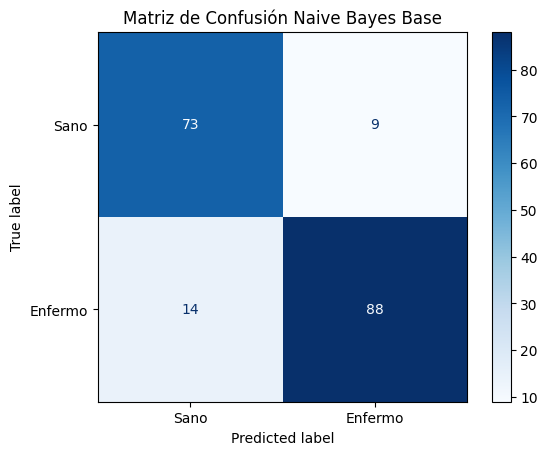

In [215]:
# calculando las predicciones y la matriz de confusión
y_pred = nb_base.predict(X_test)

# imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')

# Agregando titulo a la gráfica
plt.title('Matriz de Confusión Naive Bayes Base')
plt.show()

In [216]:
from sklearn.preprocessing import PowerTransformer
rejilla_nb = {
    "modelo__priors":        [None, [0.7, 0.3], [0.3, 0.7]],
    "modelo__var_smoothing": [1e-9, 1e-6, 1e-3, 0.01, 0.1, 1, 10],
}

In [217]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(nb_base, rejilla_nb, scoring= metrica, cv=5, n_jobs= -1)
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {round(busqueda.best_score_, 3)}, {busqueda.best_params_}')

accuracy >> 0.854, {'modelo__priors': [0.3, 0.7], 'modelo__var_smoothing': 0.01}
precision >> 0.898, {'modelo__priors': [0.7, 0.3], 'modelo__var_smoothing': 1}
recall >> 1.0, {'modelo__priors': [0.3, 0.7], 'modelo__var_smoothing': 10}
f1 >> 0.871, {'modelo__priors': [0.3, 0.7], 'modelo__var_smoothing': 0.01}
roc_auc >> 0.914, {'modelo__priors': None, 'modelo__var_smoothing': 0.01}


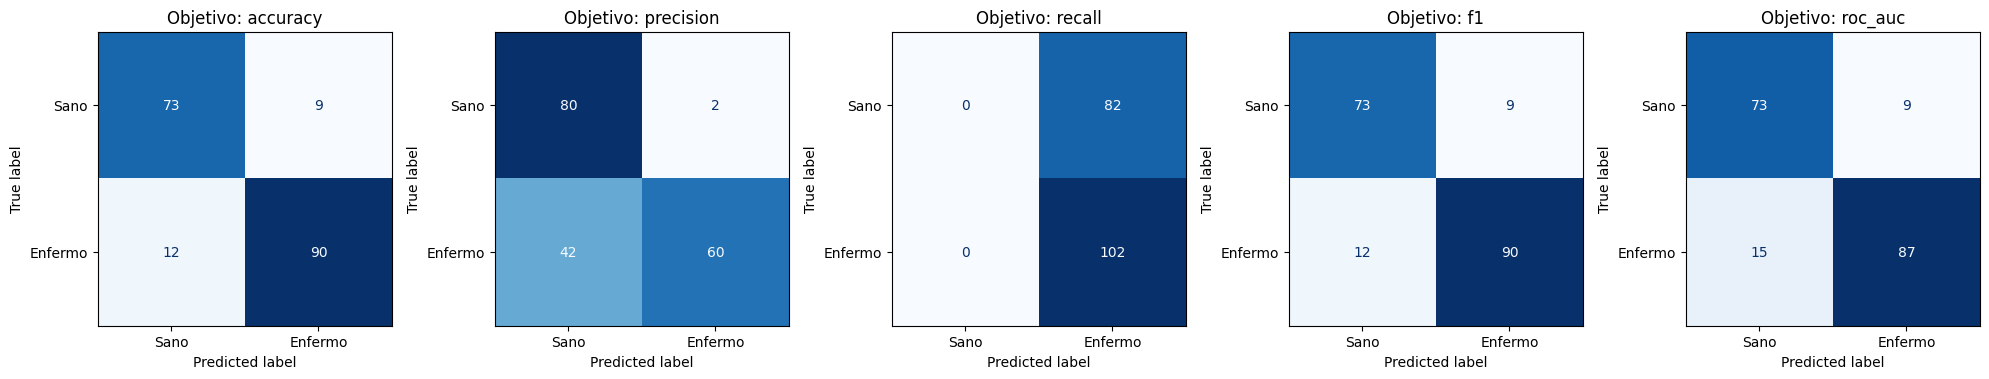

In [218]:
# Mostrando todas las matrices de confusión
fig, ejes = plt.subplots(1, 5, figsize=(20, 4))      # 1 fila con 5 recuadros

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap="Blues", colorbar=False, ax=eje)
    eje.set_title(f"Objetivo: {metrica}")

plt.tight_layout()
plt.show()

# Arbol de Decision

### Sus hiperparámetros
| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`max_depth`** | Cuántas preguntas seguidas puede hacer (los "pisos" del árbol). Pocos pisos = reglas simples. `None` = sin límite: sigue preguntando hasta que cada hoja tenga pacientes de una sola clase… aunque sea uno solo. | 2 · 3 · 4 · 5 · 6 · 8 · `None` |
| **`min_samples_leaf`** | Mínimo de pacientes en cada hoja. Impide reglas basadas en 1 o 2 pacientes raros. | 1 · 5 · 10 · 20 |
| **`criterion`** | La fórmula que mide qué tan "revuelto" queda un grupo. `"gini"` y `"entropy"` miden lo mismo de dos formas; suelen dar árboles parecidos. | `"gini"` · `"entropy"` |
| **`class_weight`** | Igual que en los modelos anteriores. | `None` · `"balanced"` |

In [219]:
# Creando el modelo base
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Pipeline: preparación → modelo
dtree_base = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("modelo", DecisionTreeClassifier(random_state = 42))
])

# Ajustando modelo con valores por defecto
dtree_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a f

              precision    recall  f1-score   support

        Sano       0.70      0.72      0.71        82
     Enfermo       0.77      0.75      0.76       102

    accuracy                           0.74       184
   macro avg       0.74      0.74      0.74       184
weighted avg       0.74      0.74      0.74       184



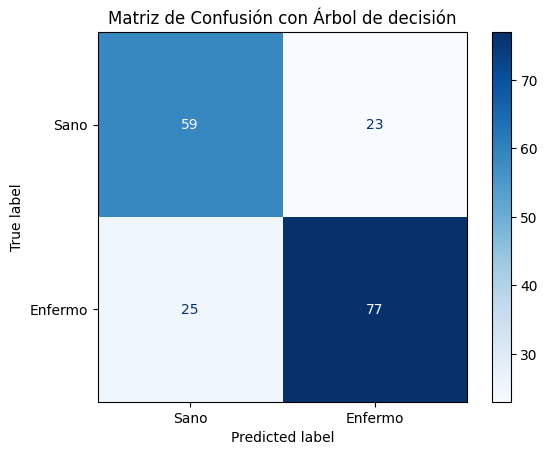

In [220]:
# calculando las predicciones y la matriz de confusión
y_pred = dtree_base.predict(X_test)

# imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')

# Agregando titulo a la gráfica
plt.title('Matriz de Confusión con Árbol de decisión')
plt.show()

In [221]:
arbol = dtree_base.named_steps["modelo"]

print("Pisos (profundidad):        ", arbol.get_depth())
print("Hojas (decisiones finales): ", arbol.get_n_leaves())

Pisos (profundidad):         15
Hojas (decisiones finales):  118


In [222]:
rejilla_arbol = {
    "modelo__max_depth":        [2, 3, 4, 5, 6, 8, None],     # None = sin límite
    "modelo__min_samples_leaf": [1, 5, 10, 20],
    "modelo__criterion":        ["gini", "entropy"],
    "modelo__class_weight":     [None, "balanced"],
}
# 7 × 4 × 2 × 2 = 112 combinaciones (muchas, pero cada árbol tarda milisegundos)

In [223]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(dtree_base, rejilla_arbol, scoring= metrica, cv=5, n_jobs= -1)
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {round(busqueda.best_score_, 3)}, {busqueda.best_params_}')

accuracy >> 0.843, {'modelo__class_weight': 'balanced', 'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 20}
precision >> 0.866, {'modelo__class_weight': None, 'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5}
recall >> 0.884, {'modelo__class_weight': None, 'modelo__criterion': 'gini', 'modelo__max_depth': 4, 'modelo__min_samples_leaf': 10}
f1 >> 0.86, {'modelo__class_weight': 'balanced', 'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 20}
roc_auc >> 0.903, {'modelo__class_weight': 'balanced', 'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 20}


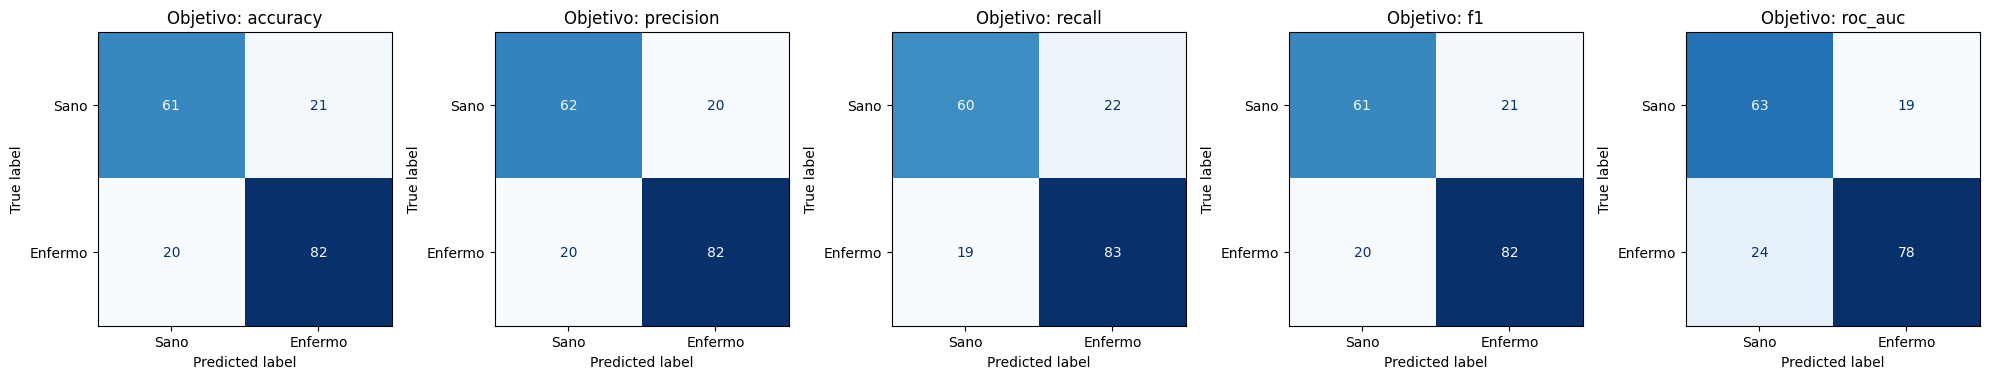

In [224]:
# Mostrando todas las matrices de confusión
fig, ejes = plt.subplots(1, 5, figsize=(20, 4))      # 1 fila con 5 recuadros

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap="Blues", colorbar=False, ax=eje)
    eje.set_title(f"Objetivo: {metrica}")

plt.tight_layout()
plt.show()

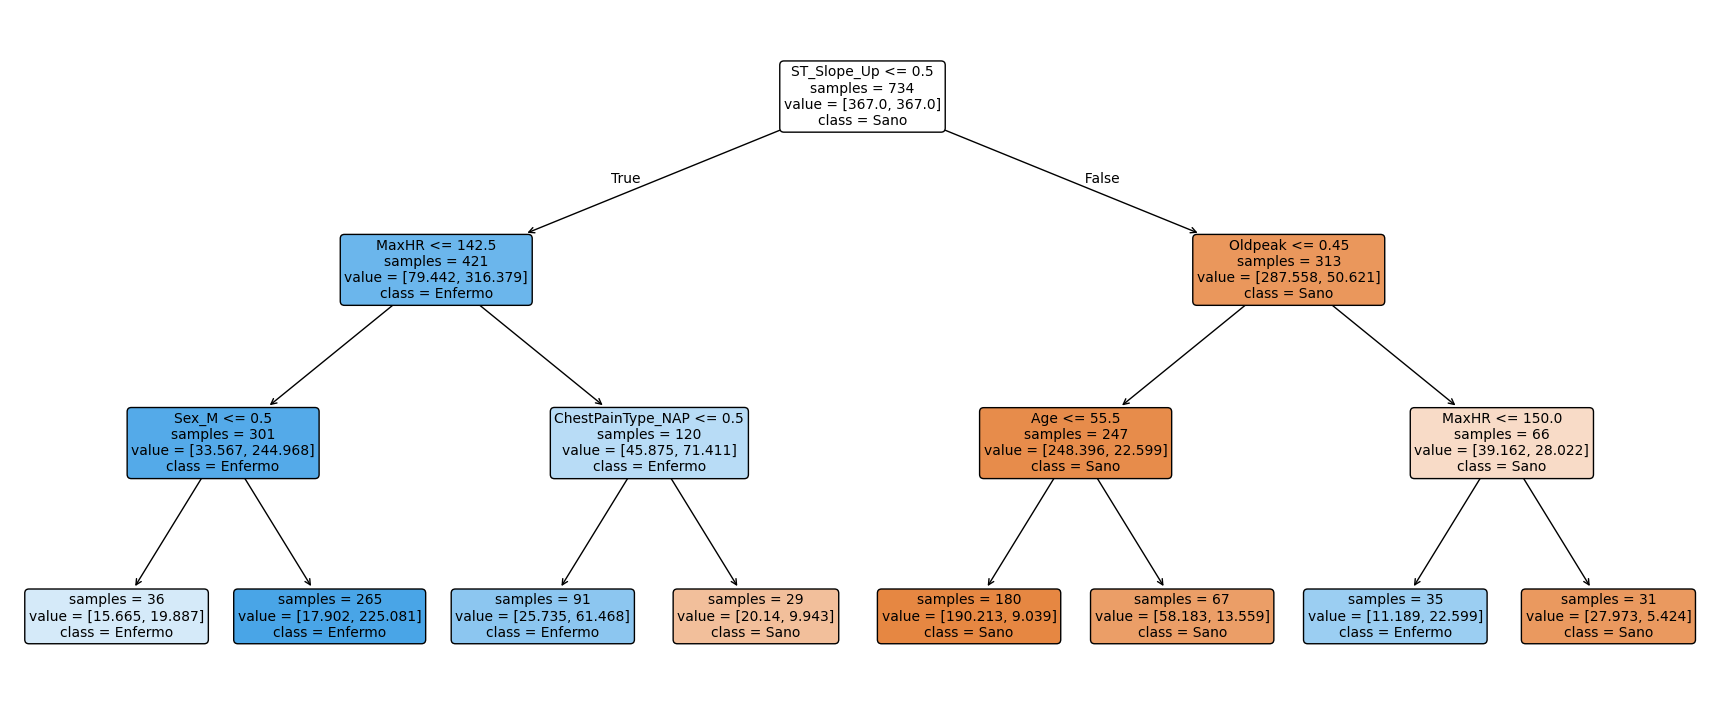

In [225]:
plt.figure(figsize=(22, 9))
plot_tree(mejores_modelos["f1"].named_steps["modelo"], feature_names=X.columns,
          class_names=clases, filled=True, rounded=True, impurity=False, fontsize=10)
plt.show()

### Sus hiperparámetros
| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`n_estimators`** | Cuántos árboles votan. Más árboles = votación más estable, pero más lenta. Agregar árboles casi nunca empeora el modelo. | 100 · 300 |
| **`max_features`** | Entre cuántas variables puede elegir cada árbol en cada pregunta. `"sqrt"` = raíz de 15 ≈ **3 variables al azar** (árboles distintos entre sí). `None` = **las 15** (todos los árboles se parecen mucho). Es la parte "aleatoria" del bosque. | `"sqrt"` · `None` |
| **`max_depth`** | Igual que en el árbol: cuántos pisos puede tener cada árbol. | 5 · `None` |
| **`class_weight`** | Igual que en los modelos anteriores. | `None` · `"balanced"` |

In [226]:
# Creando el modelo base
from sklearn.ensemble import RandomForestClassifier

# Pipeline: preparación → modelo
rforest_base = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("modelo", RandomForestClassifier(random_state = 42))
])

# Ajustando modelo con valores por defecto
rforest_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a f

              precision    recall  f1-score   support

        Sano       0.86      0.87      0.86        82
     Enfermo       0.89      0.88      0.89       102

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.88      0.88      0.88       184



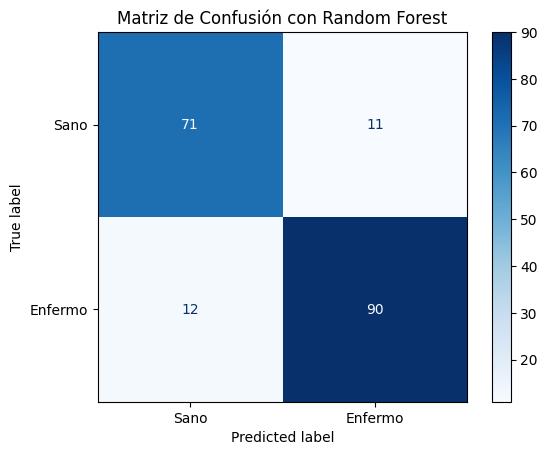

In [227]:
# calculando las predicciones y la matriz de confusión
y_pred = rforest_base.predict(X_test)

# imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')

# Agregando titulo a la gráfica
plt.title('Matriz de Confusión con Random Forest')
plt.show()

In [228]:
rejilla_bosque = {
    "modelo__n_estimators": [100, 300],
    "modelo__max_features": ["sqrt", None],      # ≈ 3 variables al azar · las 15
    "modelo__max_depth":    [5, None],
    "modelo__class_weight": [None, "balanced"],
}
# 2 × 2 × 2 × 2 = 16 combinaciones (pocas, porque cada una entrena cientos de árboles)

In [ ]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(rforest_base, rejilla_bosque, scoring= metrica, cv=5, n_jobs= -1)
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {round(busqueda.best_score_, 3)}, {busqueda.best_params_}')

accuracy >> 0.866, {'modelo__class_weight': None, 'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__n_estimators': 100}
precision >> 0.865, {'modelo__class_weight': None, 'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__n_estimators': 100}
recall >> 0.906, {'modelo__class_weight': None, 'modelo__max_depth': 5, 'modelo__max_features': 'sqrt', 'modelo__n_estimators': 300}
f1 >> 0.881, {'modelo__class_weight': None, 'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__n_estimators': 100}


In [ ]:
# Mostrando todas las matrices de confusión
fig, ejes = plt.subplots(1, 5, figsize=(20, 4))      # 1 fila con 5 recuadros

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap="Blues", colorbar=False, ax=eje)
    eje.set_title(f"Objetivo: {metrica}")

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(22, 9))
plot_tree(mejores_modelos["f1"].named_steps["modelo"], feature_names=X.columns,
          class_names=clases, filled=True, rounded=True, impurity=False, fontsize=10)
plt.show()